# Family survival

How the share of a family that survives changes with family size, and within each size with fare, cabin deck, class and ticket type.

**Families.** Families are the households from `families_v3.ipynb` (`FamilyId` in `data/complete_data.csv`). Family size is the number of passengers in the household. Passengers with SibSp + Parch = 0 are shown as **Alone** for comparison. The 8 passengers who have family aboard but no match found are left out.

**Survival.** Only train.csv has `Survived`, so a family's survival share is worked out from its train members. A family of 4 with 3 members in train, 2 of whom survived, counts as 67% survived and 33% died. Families with no member in train are left out. Each family counts once, whatever its size, and the charts show the **average share of the family that survived**. The share that died is 100% minus that.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from IPython.display import display, Markdown

SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
C_SURV, C_DIED, NEUTRAL = "#2a78d6", "#eb6834", "#f0efec"
plt.rcParams.update({
    "font.family": ["Helvetica Neue", "Arial", "DejaVu Sans"], "font.size": 9.5,
    "text.color": INK, "axes.edgecolor": AXIS, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2,
    "axes.facecolor": SURFACE, "figure.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110,
})

def find_data():
    from pathlib import Path
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "data" / "complete_data.csv").exists():
            return p / "data" / "complete_data.csv"
c = pd.read_csv(find_data())

# Fare is the price of the whole ticket, so divide by the passengers on that ticket
c["TicketCount"] = c.groupby("Ticket")["PassengerId"].transform("size")
c["FarePP"] = c["Fare"] / c["TicketCount"]

def raw_prefix(t):
    parts = t.split(" ")
    if t.replace(" ", "").isdigit():
        return ""
    return " ".join(parts[:-1]) if parts[-1].isdigit() else t
c["TicketType"] = c["Ticket"].map(lambda t: "Number only" if raw_prefix(t) == "" else re.sub(r"[./ ]", "", raw_prefix(t)).upper())
c["Deck"] = c["Cabin"].str[0]
TT_NAME = (c[c["TicketType"] != "Number only"].assign(P=c["Ticket"].map(raw_prefix))
           .groupby("TicketType")["P"].agg(lambda s: s.value_counts().index[0]))
TT_NAME["Number only"] = "Number only"
TT_NAME["Other prefixes"] = "Other prefixes"

# Unit of analysis: a family, or a passenger travelling alone
alone = (c["SibSp"] + c["Parch"]) == 0
c["Unit"] = np.where(alone, "A" + c["PassengerId"].astype(str), "F" + c["FamilyId"].astype("Int64").astype(str))
c = c[alone | (c["FamilyCheck"] != "No match found")]
c["Size"] = c.groupby("Unit")["PassengerId"].transform("size")

def mode(s):
    s = s.dropna()
    return s.mode().iloc[0] if len(s) else np.nan

units = c.groupby("Unit").agg(
    Size=("Size", "first"),
    Alone=("Unit", lambda s: s.iloc[0].startswith("A")),
    InTrain=("Survived", "count"),
    Survived=("Survived", "sum"),
    Pclass=("Pclass", mode),
    TicketType=("TicketType", mode),
    Deck=("Deck", mode),
    FarePP=("FarePP", "median"),
)
units["SurvShare"] = units["Survived"] / units["InTrain"]
units["SizeLabel"] = np.where(units["Alone"], "Alone", units["Size"].astype(str))
SIZES = ["Alone"] + [str(s) for s in sorted(units.loc[~units["Alone"], "Size"].unique())]
known = units[units["InTrain"] > 0].copy()
OVERALL = c["Survived"].mean()

fam_all = units[~units["Alone"]]
fam_known = known[~known["Alone"]]
display(Markdown(
    f"{len(fam_all)} families, {int(fam_all['Size'].sum())} passengers. "
    f"{len(fam_known)} families have at least one member in train and appear in the charts. "
    f"{int(known['Alone'].sum())} train passengers travelled alone. "
    f"The survival rate for all train passengers is {OVERALL:.0%}."
))

187 families, 511 passengers. 174 families have at least one member in train and appear in the charts. 537 train passengers travelled alone. The survival rate for all train passengers is 38%.

## Do families share cabin, class, ticket type and fare?

Mostly, yes. For each feature, the share of families where every member has the same value. Fare is compared per person, because `Fare` is the price of the whole ticket: a family of 4 on one ticket paying 31.39 paid about 7.85 each.

In [2]:
g = c[~c["Unit"].str.startswith("A")].groupby("Unit")
deck_state = g["Deck"].apply(lambda s: "none" if s.isna().all() else "all" if s.notna().all() and s.nunique() == 1
                             else "split" if s.nunique() > 1 else "partial")
ratio = g["FarePP"].agg(lambda s: s.max() / s.min() if s.min() > 0 else np.nan)
rows = [
    ("Class", (g["Pclass"].nunique() == 1).mean(), f"{int((g['Pclass'].nunique() > 1).sum())} family mixes classes"),
    ("Ticket type", (g["TicketType"].nunique() == 1).mean(), "the rest are relatives on separate tickets"),
    ("Exact ticket", (g["Ticket"].nunique() == 1).mean(), "relatives often hold consecutive tickets"),
    ("Fare per person, identical", (ratio < 1.0001).mean(), ""),
    ("Fare per person, within 25%", (ratio <= 1.25).mean(), ""),
    ("Cabin deck, same and recorded for all", (deck_state == "all").mean(), "no family is spread over two decks"),
    ("Cabin deck, recorded for nobody", (deck_state == "none").mean(), ""),
    ("Cabin deck, recorded for some members only", (deck_state == "partial").mean(), ""),
]
t = pd.DataFrame(rows, columns=["Feature", "Share of families", "Note"])
t["Share of families"] = (100 * t["Share of families"]).round(1).astype(str) + "%"
display(t.style.hide(axis="index"))
display(Markdown(
    "Where members differ, each family takes its most common value. For deck, missing cabins are ignored, "
    "so a family with any member's cabin recorded takes that deck. For fare, the family takes the median fare per person."
))

Feature,Share of families,Note
Class,99.5%,1 family mixes classes
Ticket type,95.2%,the rest are relatives on separate tickets
Exact ticket,82.9%,relatives often hold consecutive tickets
"Fare per person, identical",90.4%,
"Fare per person, within 25%",95.2%,
"Cabin deck, same and recorded for all",34.2%,no family is spread over two decks
"Cabin deck, recorded for nobody",63.6%,
"Cabin deck, recorded for some members only",2.1%,


Where members differ, each family takes its most common value. For deck, missing cabins are ignored, so a family with any member's cabin recorded takes that deck. For fare, the family takes the median fare per person.

## Survival by family size

Left: the average share of each family that survived. Right: for families with at least two members in train, whether everyone survived, everyone died, or the family was split.

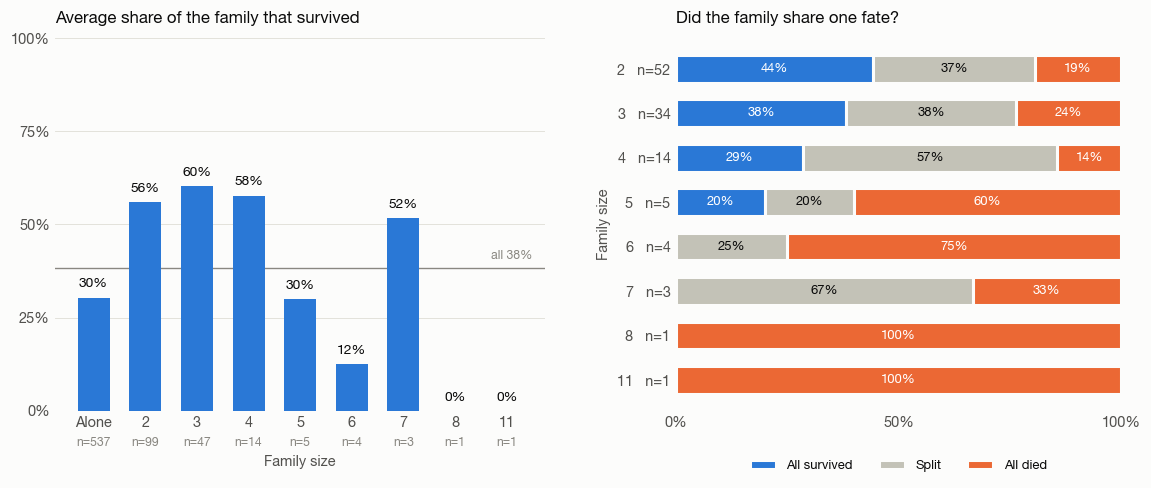

114 families have two or more members in train. In 61% of them every member shared the same fate. In 42 of the 44 split families, every member who died was male.

In [3]:
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.4), gridspec_kw={"width_ratios": [1.1, 1], "wspace": 0.28})
s = known.groupby("SizeLabel")["SurvShare"].agg(["mean", "size"]).reindex(SIZES)
x = np.arange(len(SIZES))
ax.bar(x, s["mean"], width=0.62, color=C_SURV, zorder=3)
for i, (m, n) in enumerate(zip(s["mean"], s["size"])):
    ax.text(i, m + 0.02, f"{m:.0%}", ha="center", va="bottom", fontsize=9, color=INK)
    ax.text(i, -0.07, f"n={n}", ha="center", va="top", fontsize=8, color=MUTED)
ax.axhline(OVERALL, color=MUTED, linewidth=0.9, zorder=2)
ax.text(len(SIZES) - 0.5, OVERALL + 0.015, f"all {OVERALL:.0%}", ha="right", va="bottom", fontsize=8, color=MUTED)
ax.set_xticks(x, SIZES); ax.set_ylim(0, 1); ax.set_yticks([0, .25, .5, .75, 1], ["0%", "25%", "50%", "75%", "100%"])
ax.set_xlabel("Family size", labelpad=16)
ax.set_title("Average share of the family that survived", loc="left", fontsize=11, pad=10)

multi = fam_known[fam_known["InTrain"] >= 2].copy()
multi["Outcome"] = np.select([multi["SurvShare"] == 1, multi["SurvShare"] == 0], ["All survived", "All died"], "Split")
o = pd.crosstab(multi["SizeLabel"], multi["Outcome"], normalize="index").reindex([z for z in SIZES[1:] if z in multi["SizeLabel"].values])
cnt = multi["SizeLabel"].value_counts()
cols = [("All survived", C_SURV), ("Split", "#c3c2b7"), ("All died", C_DIED)]
y = np.arange(len(o))
left = np.zeros(len(o))
for k, col in cols:
    v = o.get(k, pd.Series(0, index=o.index)).values
    ax2.barh(y, v, left=left, height=0.62, color=col, edgecolor=SURFACE, linewidth=2, label=k, zorder=3)
    for i, (l, w) in enumerate(zip(left, v)):
        if w >= 0.12:
            ax2.text(l + w / 2, i, f"{w:.0%}", ha="center", va="center", fontsize=8.5,
                     color="white" if col != "#c3c2b7" else INK)
    left += v
ax2.set_yticks(y, [f"{z}   n={cnt[z]}" for z in o.index]); ax2.invert_yaxis()
ax2.set_xlim(0, 1); ax2.set_xticks([0, .5, 1], ["0%", "50%", "100%"])
ax2.set_ylabel("Family size")
ax2.set_title("Did the family share one fate?", loc="left", fontsize=11, pad=10)
ax2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, frameon=False, fontsize=8.5)
for a in (ax, ax2):
    for sp in a.spines.values():
        sp.set_visible(False)
ax.grid(axis="y", color=GRID, linewidth=0.6); ax.tick_params(length=0); ax2.tick_params(length=0)
plt.show()

tog = (multi["Outcome"] != "Split").mean()
tr = c[c["Survived"].notna()]
split_units = multi[multi["Outcome"] == "Split"].index
n_split = len(split_units)
split_male = sum((tr[(tr["Unit"] == u) & (tr["Survived"] == 0)]["Sex"] == "male").all() for u in split_units)
display(Markdown(
    f"{len(multi)} families have two or more members in train. In {tog:.0%} of them every member shared the same fate. "
    f"In {int(split_male)} of the {int(n_split)} split families, every member who died was male."
))

Families of 2 to 4 survived at 56 to 60% on average, against 30% for passengers travelling alone. From 5 members up the share falls: 30% at 5, 12% at 6, and none of the families of 8 or 11 survived. The 3 families of 7 average 52%, but 3 families is too few to read as a rate. Most families shared one fate, and where they split it was the men who died.

In [4]:
CMAP = LinearSegmentedColormap.from_list("died_surv", [C_DIED, NEUTRAL, C_SURV])
NORM = TwoSlopeNorm(vmin=0, vcenter=OVERALL, vmax=1)

def heat(feature, order, labels, title, ylabel):
    d = known[known[feature].isin(order)]
    m = d.pivot_table(index=feature, columns="SizeLabel", values="SurvShare", aggfunc="mean").reindex(index=order, columns=SIZES)
    n = d.pivot_table(index=feature, columns="SizeLabel", values="SurvShare", aggfunc="size").reindex(index=order, columns=SIZES)
    fig, ax = plt.subplots(figsize=(11.5, 0.55 * len(order) + 1.6))
    ax.imshow(np.ma.masked_invalid(m.values.astype(float)), cmap=CMAP, norm=NORM, aspect="auto")
    for i in range(len(order)):
        for j in range(len(SIZES)):
            v = m.values[i, j]
            if pd.isna(v):
                continue
            far = v >= 0.85 or v <= 0.1
            ax.text(j, i - 0.12, f"{v:.0%}", ha="center", va="center", fontsize=9.5, color="white" if far else INK)
            ax.text(j, i + 0.24, f"n={int(n.values[i, j])}", ha="center", va="center", fontsize=7.5,
                    color="white" if far else INK2)
    ax.set_xticks(range(len(SIZES)), SIZES); ax.set_yticks(range(len(order)), labels)
    ax.xaxis.tick_top(); ax.xaxis.set_label_position("top")
    ax.set_xlabel("Family size", labelpad=8); ax.set_ylabel(ylabel)
    ax.set_xticks(np.arange(-.5, len(SIZES)), minor=True); ax.set_yticks(np.arange(-.5, len(order)), minor=True)
    ax.grid(which="minor", color=SURFACE, linewidth=2); ax.tick_params(which="both", length=0)
    for sp in ax.spines.values():
        sp.set_visible(False)
    ax.set_facecolor("#f6f6f4")
    ax.set_title(title, loc="left", fontsize=11, pad=12)
    plt.show()
    return m, n

display(Markdown(
    f"**Reading the grids.** Each cell is the average share of the family that survived, with n the number of families "
    f"(or lone passengers) in the cell. Blue cells are above the {OVERALL:.0%} rate for all passengers, orange below, "
    f"grey close to it. Empty cells have no family. A cell with n of 1 or 2 is one or two families and should not be read as a rate."
))

**Reading the grids.** Each cell is the average share of the family that survived, with n the number of families (or lone passengers) in the cell. Blue cells are above the 38% rate for all passengers, orange below, grey close to it. Empty cells have no family. A cell with n of 1 or 2 is one or two families and should not be read as a rate.

## Fare per person

Fare per person is the ticket fare divided by the number of passengers on that ticket. Each window includes its lower bound and excludes its upper bound.

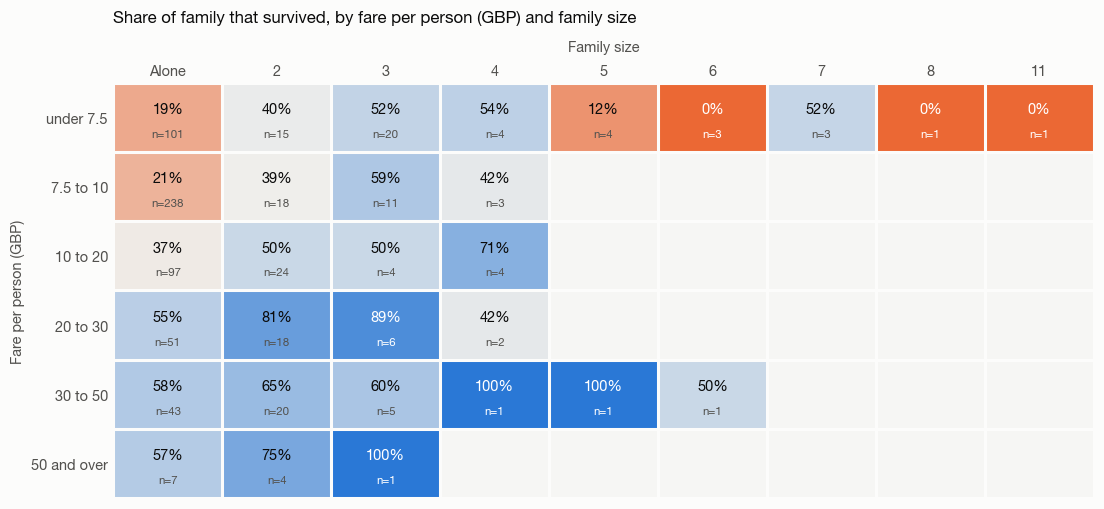

In [5]:
edges = [0, 7.5, 10, 20, 30, 50, np.inf]
flabels = ["under 7.5", "7.5 to 10", "10 to 20", "20 to 30", "30 to 50", "50 and over"]
known["FareWindow"] = pd.cut(known["FarePP"], edges, right=False, labels=flabels).astype(str)
known.loc[known["FarePP"].isna(), "FareWindow"] = "not recorded"
m, n = heat("FareWindow", flabels, flabels, "Share of family that survived, by fare per person (GBP) and family size", "Fare per person (GBP)")

Within each family size, the share that survived rises with fare per person. Families of 2 and 3 paying 20 GBP or more per person survived at 60 to 100%. The families of 8 and 11, and 3 of the 4 families of 6, paid under 7.5 per person, and none of their members in train survived.

## Cabin deck

The deck is the first letter of the cabin. Most families, like most passengers, have no cabin recorded. Decks with fewer than 3 families or lone passengers are folded into Other (G, T).

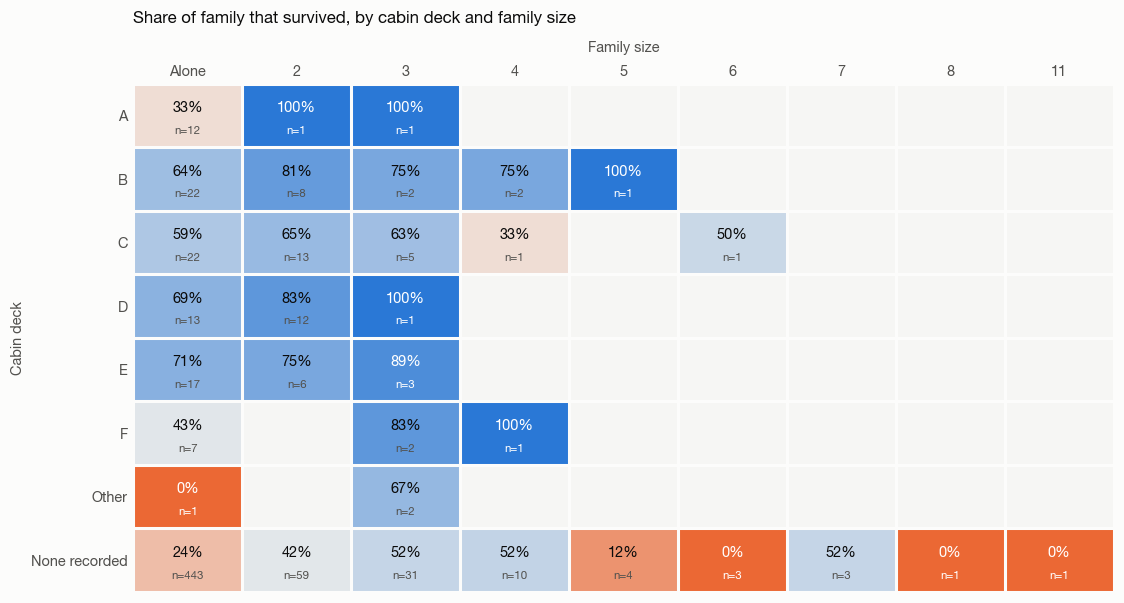

In [6]:
known["DeckGroup"] = known["Deck"].fillna("None recorded")
counts_d = known["DeckGroup"].value_counts()
known.loc[known["DeckGroup"].isin(counts_d[counts_d < 3].index), "DeckGroup"] = "Other"
order_d = [d for d in list("ABCDEF") if d in known["DeckGroup"].values] + \
          [d for d in ["Other", "None recorded"] if d in known["DeckGroup"].values]
m, n = heat("DeckGroup", order_d, order_d, "Share of family that survived, by cabin deck and family size", "Cabin deck")

Families of 2 and 3 with a cabin on decks B to E survived at 63 to 100%, against 42 to 52% for families of 2 to 4 with no cabin recorded. Every family of 6 or more except one has no cabin recorded. Cabins were mostly recorded for 1st class, so this chart largely repeats the class chart.

## Class

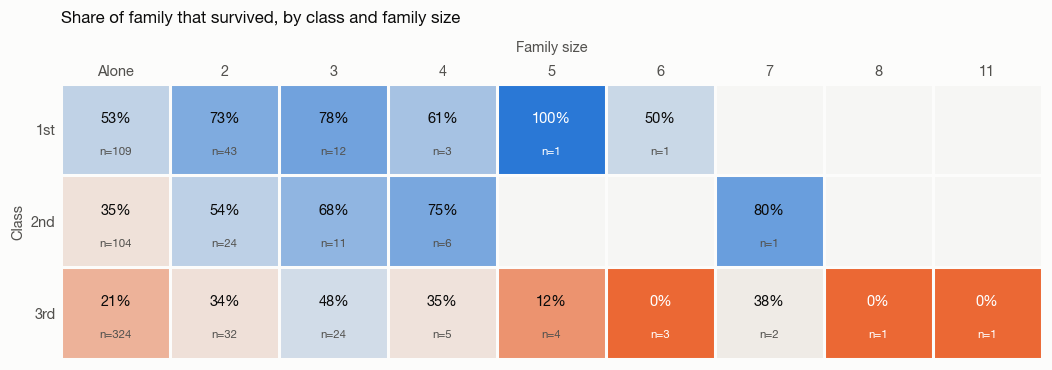

In [7]:
m, n = heat("Pclass", [1, 2, 3], ["1st", "2nd", "3rd"], "Share of family that survived, by class and family size", "Class")

Much of the family size pattern is a class pattern. 1st and 2nd class families of 2 to 4 survived at 54 to 78%, while 3rd class families of the same sizes survived at 34 to 48%. 11 of the 14 families of 5 or more are 3rd class, and they did worst: 12% at 5, 0% at 6, 8 and 11.

## Ticket type

Ticket types are as in `features_v1.ipynb`: spellings of the same prefix are merged, so `A/5` and `A./5.` are one type. Types held by fewer than 5 families or lone passengers are folded into Other prefixes.

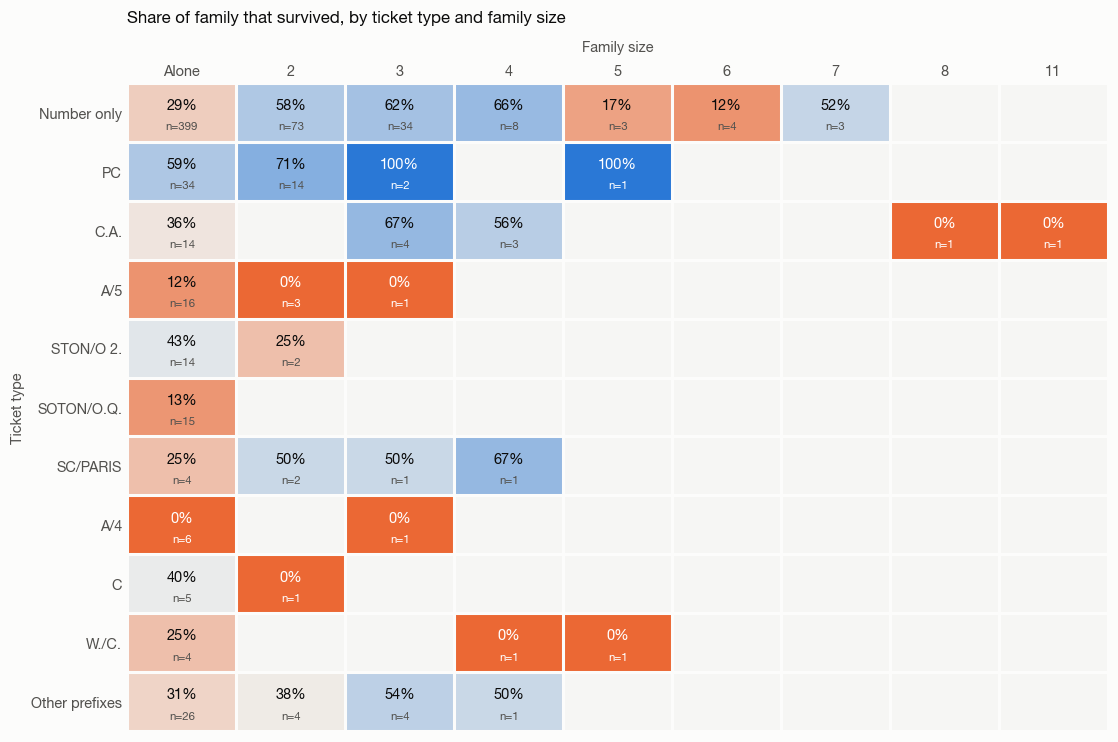

In [8]:
counts_t = known["TicketType"].value_counts()
keep = counts_t[counts_t >= 5].index
known["TicketGroup"] = np.where(known["TicketType"].isin(keep), known["TicketType"], "Other prefixes")
order_t = ["Number only"] + sorted([k for k in keep if k != "Number only"], key=lambda k: -counts_t[k]) + ["Other prefixes"]
m, n = heat("TicketGroup", order_t, [TT_NAME[k] for k in order_t], "Share of family that survived, by ticket type and family size", "Ticket type")

Ticket type mostly repeats class. PC tickets are 1st class, and PC families survived at 71 to 100%. Families on A/5, A/4 and W./C. tickets lost everyone in train. Most families hold a number-only ticket, and those follow the overall pattern: above average for 2 to 4 members, below it for 5 and 6. Most cells outside number-only and PC hold 1 to 4 families.

# Does family matter beyond the other features?

Relatives share class, fare, ticket type and often a cabin, so their shared fate could come from those features alone. The test below separates the two.

**Method**

1. **Baseline model.** Predict each train passenger's chance of survival from their own features only: sex, title (Mr, Mrs, Miss, Master, other), age (filled from the title's median where missing, with a flag), class, fare per person, cabin deck, port, ticket type, SibSp and Parch. Predictions are made out of fold: the data is split into 5 parts, and a passenger's family and ticket mates are always in the same part, so the model never sees a relative's outcome when predicting a passenger.
2. **Residual.** Each passenger's actual outcome (1 or 0) minus their predicted chance. A residual of +0.7 means they survived although the model gave them only 30%. The residual is the part of their fate the features do not explain.
3. **Pairs.** If family matters only through the features, relatives' residuals will be unrelated. If family matters in itself, relatives will tend to beat or miss the prediction together, and their residuals will correlate. Pairs of strangers who share class, fare window and sex are the control.

**Two models.** The test is run with two baseline models:

- **Logistic regression**: a linear model of the log-odds. It cannot capture interactions such as women in 3rd class surviving less often than women in 1st, and a missed interaction could look like a family effect
- **Gradient boosted trees**: builds interactions between features on its own. If the family effect survives this model too, it is not an artefact of the linear model

Correlations are Pearson's r on the residuals, from -1 to 1, where 0 means no relationship. The 95% range comes from resampling whole families and ticket groups 300 times.

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import GroupKFold
from sklearn.metrics import log_loss, roc_auc_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline


d = pd.read_csv(find_data())
d["TicketCount"] = d.groupby("Ticket")["PassengerId"].transform("size")
d["LogFare"] = np.log1p((d["Fare"] / d["TicketCount"]).fillna(d["Fare"].median()))
title = d["Name"].str.extract(r",\s*([^.]+)\.", expand=False).str.strip()
d["Title"] = title.where(title.isin(["Mr", "Mrs", "Miss", "Master"]), "Other")
d["AgeMissing"] = d["Age"].isna().astype(int)
d["AgeF"] = d["Age"].fillna(d.groupby("Title")["Age"].transform("median"))
d["DeckF"] = d["Cabin"].str[0].fillna("None")
d["EmbarkedF"] = d["Embarked"].fillna("S")
d["TT"] = d["Ticket"].map(lambda t: "NUM" if raw_prefix(t) == "" else re.sub(r"[./ ]", "", raw_prefix(t)).upper())
vc = d["TT"].value_counts()
d.loc[d["TT"].isin(vc[vc < 10].index), "TT"] = "OTHER"
d["Group"] = np.where(d["FamilyId"].notna(), "F" + d["FamilyId"].astype("Int64").astype(str), "T" + d["Ticket"])
tr = d[d["Dataset"] == "train"].reset_index(drop=True)
y = tr["Survived"].astype(int).values
CAT = ["Sex", "Pclass", "Title", "DeckF", "EmbarkedF", "TT"]
NUM = ["AgeF", "AgeMissing", "LogFare", "SibSp", "Parch"]

def make(kind, extra=()):
    if kind == "Logistic regression":
        pre = ColumnTransformer([("c", OneHotEncoder(handle_unknown="ignore"), CAT), ("n", StandardScaler(), NUM + list(extra))])
        return make_pipeline(pre, LogisticRegression(max_iter=3000))
    pre = ColumnTransformer([("c", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CAT),
                             ("n", "passthrough", NUM + list(extra))])
    return make_pipeline(pre, HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200,
                                                             categorical_features=list(range(len(CAT))), random_state=0))

FOLDS = list(GroupKFold(5).split(tr, y, tr["Group"]))
def oof(kind, frame, extra=()):
    p = np.zeros(len(frame))
    for a, b in FOLDS:
        p[b] = make(kind, extra).fit(frame.iloc[a], y[a]).predict_proba(frame.iloc[b])[:, 1]
    return p

MODELS = ["Logistic regression", "Gradient boosted trees"]
pred = {k: oof(k, tr) for k in MODELS}
res = {k: y - pred[k] for k in MODELS}

# Every pair of train passengers, sorted into one pair type
I, J = np.triu_indices(len(tr), 1)
fam = tr["FamilyId"].values
same_fam = (fam[I] == fam[J]) & ~np.isnan(fam[I])
same_tic = tr["Ticket"].values[I] == tr["Ticket"].values[J]
deck = tr["DeckF"].values
same_deck = (deck[I] == deck[J]) & (deck[I] != "None")
fw = pd.cut(np.expm1(tr["LogFare"]), [-1, 7.5, 10, 20, 30, 50, 1e9]).astype(str).values
sex = tr["Sex"].values
cls = tr["Pclass"].values
same_strat = (cls[I] == cls[J]) & (fw[I] == fw[J]) & (sex[I] == sex[J])
ptype = np.select(
    [same_fam, same_tic, same_deck, same_strat],
    ["Same family", "Same ticket, not family", "Same deck, different ticket", "Same class, fare window and sex, strangers"],
    "")
keep = ptype != ""
I, J, ptype = I[keep], J[keep], ptype[keep]
pgroup = tr["Group"].values[I]

def wcorr(a, b, w):
    x, z, w = np.r_[a, b], np.r_[b, a], np.r_[w, w]
    mx, mz = np.average(x, weights=w), np.average(z, weights=w)
    return np.average((x - mx) * (z - mz), weights=w) / np.sqrt(np.average((x - mx) ** 2, weights=w) * np.average((z - mz) ** 2, weights=w))

rng = np.random.default_rng(0)
def corr_ci(mask, r):
    a, b = r[I[mask]], r[J[mask]]
    est = wcorr(a, b, np.ones(mask.sum()))
    g = pd.Series(pgroup[mask]).astype("category")
    codes, ng = g.cat.codes.values, len(g.cat.categories)
    boot = []
    for _ in range(300):
        w = np.bincount(rng.integers(0, ng, ng), minlength=ng)[codes].astype(float)
        if w.sum() > 0:
            boot.append(wcorr(a, b, w))
    lo, hi = np.percentile(boot, [2.5, 97.5])
    return est, lo, hi

TYPES = ["Same family", "Same ticket, not family", "Same class, fare window and sex, strangers", "Same deck, different ticket"]
rows = []
for t in TYPES:
    m = ptype == t
    row = {"Pair type": t, "Pairs": int(m.sum()), "Raw survival r": wcorr(y[I[m]], y[J[m]], np.ones(m.sum()))}
    for k in MODELS:
        e, lo, hi = corr_ci(m, res[k])
        row[k] = e; row[k + " lo"] = lo; row[k + " hi"] = hi
    rows.append(row)
pairs_tab = pd.DataFrame(rows).set_index("Pair type")

perf = pd.DataFrame({k: {"AUC": roc_auc_score(y, pred[k]), "Log-loss": log_loss(y, pred[k]),
                         "Accuracy": np.mean((pred[k] > 0.5) == y)} for k in MODELS}).T
display(Markdown("**Baseline models, scored out of fold.** Higher AUC and accuracy are better, lower log-loss is better."))
display(perf.style.format({"AUC": "{:.3f}", "Log-loss": "{:.3f}", "Accuracy": "{:.1%}"}))

**Baseline models, scored out of fold.** Higher AUC and accuracy are better, lower log-loss is better.

,AUC,Log-loss,Accuracy
Logistic regression,0.866,0.427,82.5%
Gradient boosted trees,0.854,0.435,82.7%


The two baselines perform about the same (AUC 0.866 and 0.854), so the trees find little the linear model misses.

## Residual correlation by pair type

,Pairs,Raw survival r,"Residual r, logistic regression","Residual r, gradient boosted trees"
Pair type,,,,
Same family,286,+0.51,+0.45 (+0.28 to +0.57),+0.46 (+0.30 to +0.58)
"Same ticket, not family",96,+0.34,+0.41 (+0.02 to +0.51),+0.40 (+0.00 to +0.51)
"Same class, fare window and sex, strangers",45556,+0.29,+0.01 (-0.01 to +0.03),-0.01 (-0.02 to -0.00)
"Same deck, different ticket",3926,+0.01,-0.03 (-0.05 to -0.02),-0.03 (-0.05 to -0.01)


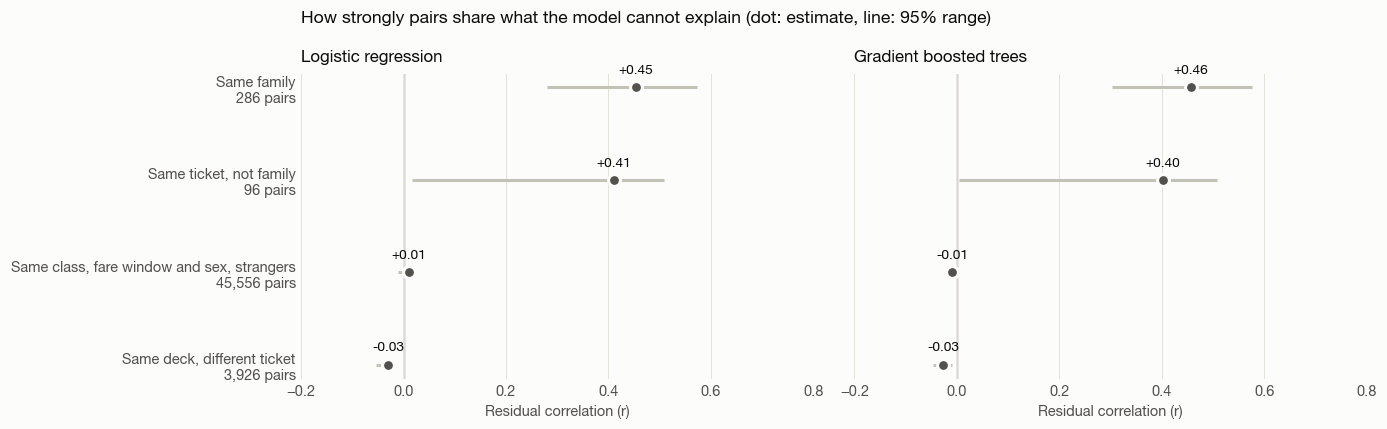

In [10]:
show = pairs_tab.copy()
for k in MODELS:
    show[k] = [f"{e:+.2f} ({lo:+.2f} to {hi:+.2f})" for e, lo, hi in zip(pairs_tab[k], pairs_tab[k + " lo"], pairs_tab[k + " hi"])]
show["Raw survival r"] = show["Raw survival r"].map(lambda v: f"{v:+.2f}")
display(show[["Pairs", "Raw survival r"] + MODELS].rename(columns={k: f"Residual r, {k.lower()}" for k in MODELS}))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.6), sharey=True, gridspec_kw={"wspace": 0.08})
yy = np.arange(len(TYPES))
for ax, k in zip(axes, MODELS):
    e, lo, hi = pairs_tab[k].values, pairs_tab[k + " lo"].values, pairs_tab[k + " hi"].values
    ax.hlines(yy, lo, hi, color=AXIS, linewidth=2, zorder=2)
    ax.scatter(e, yy, s=60, color=INK2, zorder=3, edgecolor=SURFACE, linewidth=2)
    for i, v in enumerate(e):
        ax.text(v, i - 0.12, f"{v:+.2f}", ha="center", va="bottom", fontsize=9, color=INK)
    ax.axvline(0, color=MUTED, linewidth=0.9, zorder=1)
    ax.set_xlim(-0.2, 0.8); ax.set_xlabel("Residual correlation (r)")
    ax.set_title(k, loc="left", fontsize=11, pad=8)
    ax.grid(axis="x", color=GRID, linewidth=0.6); ax.tick_params(length=0)
    for sp in ax.spines.values():
        sp.set_visible(False)
axes[0].set_yticks(yy, [f"{t}\n{n:,} pairs" for t, n in zip(TYPES, pairs_tab["Pairs"])])
axes[0].invert_yaxis()
fig.suptitle("How strongly pairs share what the model cannot explain (dot: estimate, line: 95% range)", x=0.125, ha="left", fontsize=11.5, y=1.04)
plt.show()

**Family matters beyond the other features.** Strangers who share class, fare window and sex have a raw survival correlation of 0.29, and it falls to 0 once the model accounts for their features. Their shared fate came entirely from the features. Relatives start at 0.51 and stay at 0.45 to 0.46 under both models. Most of what family tells you is not in the recorded features.

Passengers on the same ticket who are not family, mostly friends and servants travelling together, show nearly as strong an effect (0.40 to 0.41), but on only 96 pairs, so the range is wide. Sharing a deck adds nothing beyond class and fare.

## Which relatives share a fate

Family pairs split by whether the two are the same sex, and by class.

In [11]:
fm = ptype == "Same family"
groups = [("Same sex", fm & (sex[I] == sex[J])), ("Mixed sex", fm & (sex[I] != sex[J]))] + \
         [(f"{n} class", fm & (cls[I] == k)) for k, n in [(1, "1st"), (2, "2nd"), (3, "3rd")]]
rows = []
for name, m in groups:
    row = {"Family pairs": name, "Pairs": int(m.sum())}
    for k in MODELS:
        e, lo, hi = corr_ci(m, res[k])
        row[f"Residual r, {k.lower()}"] = f"{e:+.2f} ({lo:+.2f} to {hi:+.2f})"
    rows.append(row)
display(pd.DataFrame(rows).set_index("Family pairs"))

,Pairs,"Residual r, logistic regression","Residual r, gradient boosted trees"
Family pairs,,,
Same sex,127,+0.83 (+0.74 to +0.90),+0.78 (+0.66 to +0.87)
Mixed sex,159,+0.23 (-0.02 to +0.41),+0.27 (+0.03 to +0.44)
1st class,53,+0.17 (-0.10 to +0.29),+0.15 (-0.09 to +0.29)
2nd class,50,+0.24 (+0.01 to +0.36),+0.19 (-0.11 to +0.30)
3rd class,183,+0.53 (+0.26 to +0.70),+0.54 (+0.27 to +0.70)


**Relatives of the same sex share a fate almost completely** (0.78 to 0.83): mothers with daughters, and brothers. Mixed-sex pairs, mostly husbands and wives, share it much less (0.23 to 0.27), consistent with women and children being saved first. **The effect is strongest in 3rd class** (0.53 to 0.54), where families lived or died together. In 1st and 2nd class the ranges include 0.

## Does it improve prediction?

One feature is added to each model: the average residual of the passenger's labelled family members (or ticket mates), leaving the passenger out, plus a flag for whether they have any. Mates' residuals come from the out-of-fold baseline, and the folds keep whole families and tickets together, so no passenger's own outcome reaches their prediction.

In [12]:
def mates(frame, key, r):
    f = frame.assign(r=r)
    s = f.groupby(key)["r"].transform("sum"); n = f.groupby(key)["r"].transform("size")
    return ((s - f["r"]) / (n - 1)).where(n > 1, 0.0).values, (n > 1).astype(int).values

rows = []
for k in MODELS:
    base = pred[k]
    rows.append({"Model": k, "Feature added": "none (baseline)", "AUC": roc_auc_score(y, base), "Log-loss": log_loss(y, base),
                 "Accuracy, all": np.mean((base > .5) == y), "Accuracy, with a mate": np.nan, "Passengers with a mate": np.nan})
    for key, label in [("FamilyKey", "family members' residual"), ("Ticket", "ticket mates' residual")]:
        f = tr.assign(FamilyKey=tr["FamilyId"].fillna(-tr["PassengerId"]))
        f["MateRes"], f["HasMate"] = mates(f, key, res[k])
        p2 = oof(k, f, extra=("MateRes", "HasMate"))
        hm = f["HasMate"].values == 1
        rows.append({"Model": k, "Feature added": label, "AUC": roc_auc_score(y, p2), "Log-loss": log_loss(y, p2),
                     "Accuracy, all": np.mean((p2 > .5) == y),
                     "Accuracy, with a mate": f"{np.mean((base[hm] > .5) == y[hm]):.1%} to {np.mean((p2[hm] > .5) == y[hm]):.1%}",
                     "Passengers with a mate": int(hm.sum())})
pt = pd.DataFrame(rows).set_index(["Model", "Feature added"])
display(pt.style.format({"AUC": "{:.3f}", "Log-loss": "{:.3f}", "Accuracy, all": "{:.1%}", "Passengers with a mate": "{:.0f}"}, na_rep=""))

test = d[d["Dataset"] == "test"]
fam_t = test["FamilyId"].isin(set(tr["FamilyId"].dropna()))
tic_t = test["Ticket"].isin(set(tr["Ticket"]))
display(Markdown(f"In test.csv, {int((fam_t | tic_t).sum())} of {len(test)} passengers ({(fam_t | tic_t).mean():.0%}) have a family member or ticket mate in train, so the feature can help them. The rest fall back to the baseline."))

In test.csv, 171 of 418 passengers (41%) have a family member or ticket mate in train, so the feature can help them. The rest fall back to the baseline.

Adding the mates' residual improves both models. For the logistic regression, AUC rises from 0.866 to 0.888 with family members and to 0.898 with ticket mates, and accuracy for passengers with a mate rises from about 84% to 88%. Ticket mates do slightly better than family because they also cover companions who are not related.

## Conclusion

Family is informative in itself, not only through shared class, fare, ticket type or cabin. Both a linear model and a tree model leave a strong shared component between relatives that strangers with the same features do not have.

This does not show that family is the cause. The likeliest explanation is what relatives shared but the data does not record: where in the ship they were (most 3rd class cabins are missing), when they reached the boats, and that they stayed together. For prediction the distinction does not matter.

**Recommended feature:** a travelling group per passenger (family plus anyone on the same ticket), and the average residual of their labelled group mates, leaving the passenger out, with a flag for whether they have any. Build it inside each cross-validation fold as above. A second version from same-sex mates only is worth testing, since that is where the effect is strongest.

# Which family relationships share a fate

The test above treats every pair of relatives alike. Here pairs are split by relationship, using the `Relatives` column from `families_v3.ipynb` (each pair labelled spouse, sibling, parent or child) and each person's sex. Relatives in the same household who are not directly related, such as a man and his brother's wife, are their own type.

Two questions, answered separately:

1. **Do they share a fate?** For each relationship type: how often both survived, both died, or one of each, and the residual correlation from the two baseline models. A high residual correlation means the pair beat or missed their predictions together.
2. **Is a role more likely to survive?** For each role (husband, wife, father, mother, son, daughter, brother, sister): the actual survival rate against the rate the baseline predicts from their own features. A gap means being in that role matters beyond sex, age, class and fare.

Only pairs where both people are in train count. Counts are small for most types, so the 95% ranges matter more than the estimates.

In [13]:
row_of = {pid: k for k, pid in enumerate(tr["PassengerId"])}
sex_of = dict(zip(d["PassengerId"], d["Sex"]))
age_of = dict(zip(d["PassengerId"], d["Age"]))
fam_of = dict(zip(d["PassengerId"], d["FamilyId"]))

pairs = {}
for pid, relstr in zip(d["PassengerId"], d["Relatives"]):
    if not isinstance(relstr, str):
        continue
    for part in relstr.split("; "):
        role, ids = part.split(" ", 1)
        for other in map(int, ids.split(", ")):
            key = (min(pid, other), max(pid, other))
            if key in pairs:
                continue
            # store as (first, second, how second relates to first)
            pairs[key] = (pid, other, role)

def ptype_of(a, b, role):
    sa, sb = sex_of[a], sex_of[b]
    if role == "spouse":
        return "Husband and wife"
    if role == "sibling":
        return {("male", "male"): "Brothers", ("female", "female"): "Sisters"}.get((sa, sb), "Brother and sister")
    par, ch = (b, a) if role == "parent" else (a, b)
    return f"{'Father' if sex_of[par] == 'male' else 'Mother'} and {'son' if sex_of[ch] == 'male' else 'daughter'}"

rows = []
for (x, z), (a, b, role) in pairs.items():
    if a in row_of and b in row_of:
        rows.append((row_of[a], row_of[b], ptype_of(a, b, role)))
# same household, no direct relation
labelled = set(pairs)
fam_tr = tr[tr["FamilyId"].notna()]
for fid, g in fam_tr.groupby("FamilyId"):
    ids = sorted(g["PassengerId"])
    for k1 in range(len(ids)):
        for k2 in range(k1 + 1, len(ids)):
            if (ids[k1], ids[k2]) not in labelled:
                rows.append((row_of[ids[k1]], row_of[ids[k2]], "Same household, not directly related"))
RP = pd.DataFrame(rows, columns=["i", "j", "Type"])
RP["grp"] = tr["Group"].values[RP["i"]]

def ci(ii, jj, grp, r, reps=300):
    a, b = r[ii], r[jj]
    est = wcorr(a, b, np.ones(len(a)))
    codes, uniq = pd.factorize(grp)
    boot = []
    for _ in range(reps):
        w = np.bincount(rng.integers(0, len(uniq), len(uniq)), minlength=len(uniq))[codes].astype(float)
        if w.sum() > 0 and len(set(a[w > 0])) > 1 and len(set(b[w > 0])) > 1:
            boot.append(wcorr(a, b, w))
    lo, hi = np.percentile(boot, [2.5, 97.5]) if boot else (np.nan, np.nan)
    return est, lo, hi

REL_ORDER = ["Husband and wife", "Mother and daughter", "Mother and son", "Father and daughter", "Father and son",
             "Sisters", "Brothers", "Brother and sister", "Same household, not directly related"]

## Shared fate by relationship type

In [14]:
out = []
for t in REL_ORDER:
    g = RP[RP["Type"] == t]
    if len(g) == 0:
        continue
    ya, yb = y[g["i"].values], y[g["j"].values]
    row = {"Relationship": t, "Pairs": len(g),
           "Both survived": np.mean((ya == 1) & (yb == 1)), "Split": np.mean(ya != yb), "Both died": np.mean((ya == 0) & (yb == 0))}
    for k in MODELS:
        e, lo, hi = ci(g["i"].values, g["j"].values, g["grp"].values, res[k])
        row[k] = e; row[k + " lo"] = lo; row[k + " hi"] = hi
    out.append(row)
REL = pd.DataFrame(out).set_index("Relationship")

show = REL[["Pairs", "Both survived", "Split", "Both died"]].copy()
for k in MODELS:
    show[f"Residual r, {k.lower()}"] = [f"{e:+.2f} ({lo:+.2f} to {hi:+.2f})" for e, lo, hi in zip(REL[k], REL[k + " lo"], REL[k + " hi"])]
display(show.style.format({"Both survived": "{:.0%}", "Split": "{:.0%}", "Both died": "{:.0%}"}))

# Who survives when a pair splits
def split_winner(t, first_label, second_label):
    g = RP[RP["Type"] == t]
    ya, yb = y[g["i"].values], y[g["j"].values]
    m = ya != yb
    return int(m.sum())
rows = []
for t in ["Husband and wife", "Brother and sister", "Mother and son", "Father and daughter"]:
    g = RP[RP["Type"] == t]
    ia, ib = g["i"].values, g["j"].values
    female_a = tr["Sex"].values[ia] == "female"
    yf = np.where(female_a, y[ia], y[ib]); ym = np.where(female_a, y[ib], y[ia])
    m = yf != ym
    if m.sum():
        rows.append({"Relationship": t, "Split pairs": int(m.sum()), "Woman or girl survived": f"{np.mean(yf[m] == 1):.0%}",
                     "Man or boy survived": f"{np.mean(ym[m] == 1):.0%}"})
display(Markdown("**Who survived when a mixed-sex pair split**"))
display(pd.DataFrame(rows).set_index("Relationship"))

,Pairs,Both survived,Split,Both died,"Residual r, logistic regression","Residual r, gradient boosted trees"
Relationship,,,,,,
Husband and wife,45,27%,56%,18%,+0.09 (-0.03 to +0.15),+0.07 (-0.07 to +0.16)
Mother and daughter,40,57%,0%,42%,+0.98 (+0.96 to +0.99),+0.95 (+0.90 to +0.98)
Mother and son,35,29%,14%,57%,+0.52 (+0.21 to +0.65),+0.57 (+0.22 to +0.74)
Father and daughter,19,16%,47%,37%,+0.11 (-0.22 to +0.28),+0.27 (-0.25 to +0.56)
Father and son,12,8%,50%,42%,+0.14 (-0.55 to +0.47),-0.10 (-0.59 to +0.28)
Sisters,27,37%,0%,63%,+0.99 (+0.97 to +1.00),+0.88 (+0.64 to +0.99)
Brothers,43,9%,5%,86%,+0.54 (+0.14 to +0.94),+0.47 (+0.23 to +0.77)
Brother and sister,51,12%,24%,65%,+0.26 (-0.21 to +0.63),+0.37 (-0.04 to +0.62)
"Same household, not directly related",14,21%,43%,36%,-0.06 (-0.73 to +0.50),-0.19 (-0.88 to +0.41)


**Who survived when a mixed-sex pair split**

,Split pairs,Woman or girl survived,Man or boy survived
Relationship,,,
Husband and wife,25,100%,0%
Brother and sister,12,83%,17%
Mother and son,5,80%,20%
Father and daughter,9,100%,0%


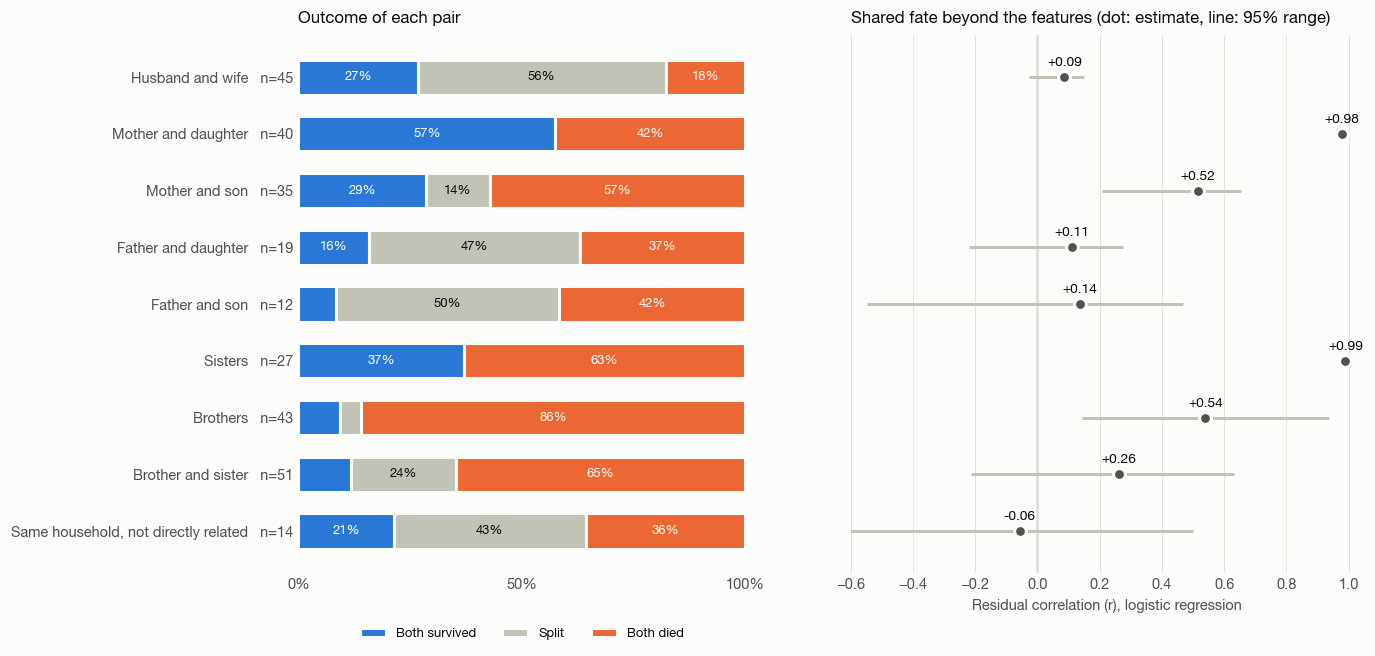

In [15]:
types = [t for t in REL_ORDER if t in REL.index]
fig, axes = plt.subplots(1, 2, figsize=(12.5, 0.55 * len(types) + 1.4), sharey=True,
                         gridspec_kw={"width_ratios": [1, 1.15], "wspace": 0.22})
yy = np.arange(len(types))
ax = axes[0]
left = np.zeros(len(types))
for col, colr, name in [("Both survived", C_SURV, "Both survived"), ("Split", "#c3c2b7", "Split"), ("Both died", C_DIED, "Both died")]:
    v = REL.loc[types, col].values
    ax.barh(yy, v, left=left, height=0.62, color=colr, edgecolor=SURFACE, linewidth=2, label=name, zorder=3)
    for i, (l, w) in enumerate(zip(left, v)):
        if w >= 0.12:
            ax.text(l + w / 2, i, f"{w:.0%}", ha="center", va="center", fontsize=8.5, color=INK if colr == "#c3c2b7" else "white")
    left += v
ax.set_xlim(0, 1); ax.set_xticks([0, .5, 1], ["0%", "50%", "100%"])
ax.set_yticks(yy, [f"{t}   n={REL.loc[t, 'Pairs']}" for t in types]); ax.invert_yaxis()
ax.set_title("Outcome of each pair", loc="left", fontsize=11, pad=8)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=3, frameon=False, fontsize=8.5)
ax2 = axes[1]
k = MODELS[0]
e, lo, hi = REL.loc[types, k].values, REL.loc[types, k + " lo"].values, REL.loc[types, k + " hi"].values
ax2.hlines(yy, lo, hi, color=AXIS, linewidth=2, zorder=2)
ax2.scatter(e, yy, s=60, color=INK2, zorder=3, edgecolor=SURFACE, linewidth=2)
for i, v in enumerate(e):
    ax2.text(v, i - 0.14, f"{v:+.2f}", ha="center", va="bottom", fontsize=9, color=INK)
ax2.axvline(0, color=MUTED, linewidth=0.9, zorder=1)
ax2.set_xlim(-0.6, 1.05); ax2.set_xlabel("Residual correlation (r), logistic regression")
ax2.set_title("Shared fate beyond the features (dot: estimate, line: 95% range)", loc="left", fontsize=11, pad=8)
for a in axes:
    a.tick_params(length=0)
    for sp in a.spines.values():
        sp.set_visible(False)
ax2.grid(axis="x", color=GRID, linewidth=0.6)
plt.show()

**Mothers and daughters, and sisters, never split.** All 40 mother and daughter pairs (from 32 families) and all 27 pairs of sisters (16 families) either both survived or both died, and their residual correlation is close to 1 under both models. Knowing one tells you the other almost for certain, even in 3rd class where the model expects women to do worse.

**Mothers and sons, and brothers, mostly share a fate** (0.47 to 0.57). Most of these sons are boys travelling with their mother. Brothers mostly died together: 86% of brother pairs, 37 of the 43 in 3rd class.

**Husbands and wives share almost nothing beyond the features** (0.07 to 0.09, range including 0). 56% of couples split, and in all 25 split couples the wife survived and the husband died. Sex already explains that, so knowing the husband's fate adds little about the wife. Fathers with their children look the same: 47 to 50% split, ranges wide and including 0.

**Brother and sister pairs fall in between** (0.26 to 0.37, ranges including 0). When they split, the sister survived in 10 of 12.

So the pattern is that female relatives, and children with their mother, live or die as a unit. Men are separated from their wives and daughters, so their fate tells you less about the rest of the family.

## Does a role change the chance of survival?

Each passenger in train with at least one labelled relative is given every role they hold: a married father with a brother aboard is a husband, a father and a brother. **Predicted** is the average chance the logistic regression baseline gives them from their own features. **Gap** is actual minus predicted: positive means people in that role survived more often than their sex, age, class and fare suggest. Passengers travelling alone are shown for comparison.

In [16]:
roles = {pid: set() for pid in tr["PassengerId"]}
for (x, z), (a, b, r) in pairs.items():
    for me, other, rel in [(a, b, r), (b, a, {"spouse": "spouse", "sibling": "sibling", "parent": "child", "child": "parent"}[r])]:
        if me not in roles:
            continue
        male = sex_of[me] == "male"
        # rel is how 'other' relates to 'me': other is my parent -> I am a child
        mine = {"spouse": "Husband" if male else "Wife", "sibling": "Brother" if male else "Sister",
                "parent": "Son" if male else "Daughter", "child": "Father" if male else "Mother"}[rel]
        roles[me].add(mine)
rows = []
p0 = pred[MODELS[0]]
for name in ["Husband", "Wife", "Father", "Mother", "Son", "Daughter", "Brother", "Sister"]:
    m = np.array([name in roles[pid] for pid in tr["PassengerId"]])
    rows.append({"Role": name, "Passengers": int(m.sum()), "Survived": y[m].mean(), "Predicted": p0[m].mean(),
                 "Gap": y[m].mean() - p0[m].mean()})
for name, sx in [("Man alone", "male"), ("Woman alone", "female")]:
    m = ((tr["SibSp"] + tr["Parch"]) == 0).values & (tr["Sex"].values == sx)
    rows.append({"Role": name, "Passengers": int(m.sum()), "Survived": y[m].mean(), "Predicted": p0[m].mean(),
                 "Gap": y[m].mean() - p0[m].mean()})
RT = pd.DataFrame(rows).set_index("Role")
display(RT.style.format({"Survived": "{:.0%}", "Predicted": "{:.0%}", "Gap": "{:+.0%}"}))

,Passengers,Survived,Predicted,Gap
Role,,,,
Husband,64,23%,20%,+3%
Wife,70,80%,80%,-0%
Father,28,11%,13%,-2%
Mother,54,69%,69%,-1%
Son,62,40%,41%,-1%
Daughter,64,62%,61%,+2%
Brother,80,26%,23%,+3%
Sister,72,60%,55%,+4%
Man alone,411,16%,16%,-1%


**No role changes the chance of survival beyond the features.** Every gap between actual and predicted is within 4 points, and passengers travelling alone show the same. Husbands survive at 23% because they are men, not because they are husbands; mothers survive at 69% because they are women, mostly in 1st and 2nd class.

**Answer to the question.** No type of family unit is more likely to survive once sex, age, class and fare are known. What family adds is shared fate, and that depends on the relationship: a mother's or sister's outcome predicts a daughter's or sister's outcome almost perfectly, while a husband's says little about his wife. For modelling, this argues for building the mates' feature from **female relatives and from a child's mother**, rather than from all relatives equally.

# Solo passengers

Passengers with SibSp + Parch = 0 travelled with no family. This section asks whether travelling alone changes the chance of survival, or whether solo passengers only look different because of who they were.

In [17]:
trs = tr.copy()
trs["Alone"] = (trs["SibSp"] + trs["Parch"]) == 0
trs["Shared"] = trs["TicketCount"] > 1
grp = trs.groupby("Alone")["Survived"].agg(["size", "mean"])
mix = trs.groupby("Alone").agg(Men=("Sex", lambda s: (s == "male").mean()), Third=("Pclass", lambda s: (s == 3).mean()),
                               Children=("Age", lambda a: (a < 16).sum() / a.notna().sum()))
t = pd.DataFrame({"Passengers": grp["size"], "Survived": grp["mean"], "Men": mix["Men"], "3rd class": mix["Third"],
                  "Under 16 (where age known)": mix["Children"]}).rename(index={True: "Alone", False: "With family"})
display(t.style.format({"Survived": "{:.0%}", "Men": "{:.0%}", "3rd class": "{:.0%}", "Under 16 (where age known)": "{:.0%}"}))

,Passengers,Survived,Men,3rd class,Under 16 (where age known)
Alone,,,,,
With family,354,51%,47%,47%,25%
Alone,537,30%,77%,60%,1%


Solo passengers survived at 30%, against 51% for passengers with family. But they are a different mix of people: 77% are men against 47%, 60% are in 3rd class against 47%, and only 1% are under 16 against 25%. Men and 3rd class passengers survived least, so the raw gap mostly reflects who travelled alone. The chart below compares like with like.

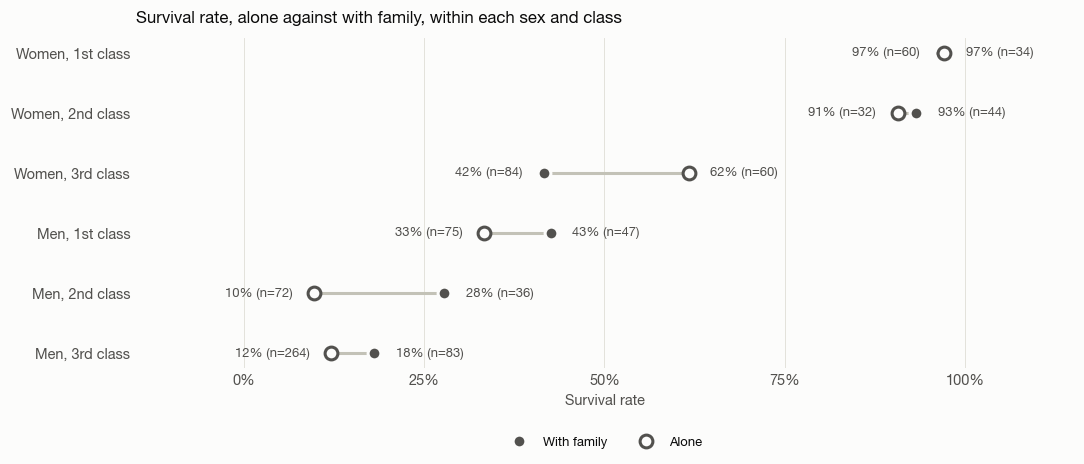

In [18]:
cells_ = [(sx, k) for sx in ["female", "male"] for k in [1, 2, 3]]
fig, ax = plt.subplots(figsize=(11, 3.9))
yy = np.arange(len(cells_))
for i, (sx, k) in enumerate(cells_):
    g = trs[(trs["Sex"] == sx) & (trs["Pclass"] == k)]
    a, f = g[g["Alone"]], g[~g["Alone"]]
    ra, rf = a["Survived"].mean(), f["Survived"].mean()
    ax.plot([ra, rf], [i, i], color=AXIS, linewidth=2, zorder=2)
    ax.scatter(rf, i, s=70, color=INK2, zorder=3, edgecolor=SURFACE, linewidth=2, label="With family" if i == 0 else None)
    ax.scatter(ra, i, s=70, facecolor=SURFACE, edgecolor=INK2, linewidth=2, zorder=4, label="Alone" if i == 0 else None)
    for r, n, side in [(ra, len(a), "a"), (rf, len(f), "f")]:
        off = -0.03 if (side == "a") == (ra < rf) else 0.03
        ax.text(r + off, i, f"{r:.0%} (n={n})", ha="right" if off < 0 else "left", va="center", fontsize=8.5, color=INK2)
ax.set_yticks(yy, [f"{'Women' if sx == 'female' else 'Men'}, {k}{'st' if k == 1 else 'nd' if k == 2 else 'rd'} class" for sx, k in cells_])
ax.invert_yaxis(); ax.set_xlim(-0.15, 1.15); ax.set_xticks([0, .25, .5, .75, 1], ["0%", "25%", "50%", "75%", "100%"])
ax.set_xlabel("Survival rate")
ax.set_title("Survival rate, alone against with family, within each sex and class", loc="left", fontsize=11, pad=10)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2, frameon=False, fontsize=8.5)
ax.grid(axis="x", color=GRID, linewidth=0.6); ax.tick_params(length=0)
for sp in ax.spines.values():
    sp.set_visible(False)
plt.show()

Within the same sex and class the gap mostly disappears or reverses. 1st and 2nd class women survived at 91 to 97% either way. **Women in 3rd class did better alone (62%) than with family (42%)**: 3rd class mothers and daughters often stayed together and died together, as the relationship analysis showed. **Men did worse alone**: 10% against 28% in 2nd class and 33% against 43% in 1st, while 3rd class men were low either way (12% and 18%). Men with family include boys, who were saved with their mothers, which accounts for much of their advantage.

## Alone, or alone with companions?

A solo passenger can still share a ticket with people who are not family: friends, servants or employers. Solo passengers are split here by whether anyone else in the full data holds their ticket.

In [19]:
a = trs[trs["Alone"]]
t = a.groupby(["Sex", "Shared"])["Survived"].agg(["size", "mean"]).reset_index()
t["Sex"] = t["Sex"].map({"female": "Women", "male": "Men"})
t["Ticket"] = t["Shared"].map({True: "Shared with non-family", False: "Own ticket"})
display(t[["Sex", "Ticket", "size", "mean"]].rename(columns={"size": "Passengers", "mean": "Survived"})
        .style.format({"Survived": "{:.0%}"}).hide(axis="index"))

Sex,Ticket,Passengers,Survived
Women,Own ticket,91,73%
Women,Shared with non-family,35,94%
Men,Own ticket,357,15%
Men,Shared with non-family,54,17%


Solo women who shared a ticket with non-family survived at 94%, against 73% for solo women on their own ticket. But 27 of those 35 women are in 1st class, against 7 of the 91 on their own ticket, so most of the gap is class. For solo men a shared ticket makes almost no difference (17% against 15%).

## Does travelling alone add anything to the model?

The baseline already contains SibSp and Parch, so it already knows who is alone. The test adds an `Alone` flag (SibSp + Parch = 0) and an `AloneSharedTicket` flag, and also tries replacing SibSp and Parch with the `Alone` flag only. Each version is scored with 10 repeats of 5-fold cross-validation, keeping families and tickets together, and compared on the same folds. Change in log-loss is the new version minus the baseline, so negative is better.

**Gap** is the solo passengers' actual survival minus what the logistic regression baseline predicted for them: positive means they did better than their features suggest.

In [20]:
trs["AloneF"] = trs["Alone"].astype(int)
trs["AloneSharedTicket"] = (trs["Alone"] & trs["Shared"]).astype(int)
groups_ = trs["Group"].values
ug = np.unique(groups_)
def folds_(seed):
    r = np.random.default_rng(seed); f = dict(zip(ug[r.permutation(len(ug))], np.arange(len(ug)) % 5))
    fi = np.array([f[g] for g in groups_]); return [(np.where(fi != k)[0], np.where(fi == k)[0]) for k in range(5)]
REP = [folds_(s) for s in range(10)]
def make_cfg(kind, num):
    if kind == "Logistic regression":
        pre = ColumnTransformer([("c", OneHotEncoder(handle_unknown="ignore"), CAT), ("n", StandardScaler(), num)])
        return make_pipeline(pre, LogisticRegression(max_iter=3000))
    pre = ColumnTransformer([("c", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CAT), ("n", "passthrough", num)])
    return make_pipeline(pre, HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200,
                                                             categorical_features=list(range(len(CAT))), random_state=0))
def score_(kind, num):
    out = []
    for F in REP:
        p = np.zeros(len(trs))
        for a_, b_ in F:
            p[b_] = make_cfg(kind, num).fit(trs.iloc[a_], y[a_]).predict_proba(trs.iloc[b_])[:, 1]
        out.append((log_loss(y, p), np.mean((p > .5) == y)))
    return np.array(out)
base_num = ["AgeF", "AgeMissing", "LogFare", "SibSp", "Parch"]
no_fam = ["AgeF", "AgeMissing", "LogFare"]
configs = [("Baseline (with SibSp and Parch)", base_num), ("+ Alone", base_num + ["AloneF"]),
           ("+ Alone + AloneSharedTicket", base_num + ["AloneF", "AloneSharedTicket"]),
           ("SibSp and Parch replaced by Alone", no_fam + ["AloneF"]), ("No family information at all", no_fam)]
rows = []
for k in MODELS:
    base = score_(k, base_num)
    for name, num in configs:
        sc = base if name.startswith("Baseline") else score_(k, num)
        dl = sc[:, 0] - base[:, 0]
        rows.append({"Model": k, "Version": name, "Log-loss": sc[:, 0].mean(),
                     "Change": "" if name.startswith("Baseline") else f"{dl.mean():+.4f} (better in {int((dl < 0).sum())} of 10)",
                     "Accuracy": sc[:, 1].mean()})
display(pd.DataFrame(rows).set_index(["Model", "Version"]).style.format({"Log-loss": "{:.4f}", "Accuracy": "{:.1%}"}))

al = trs["Alone"].values
p0 = pred[MODELS[0]]
gap = []
for sx in ["female", "male"]:
    for k in [1, 2, 3]:
        m = al & (trs["Sex"].values == sx) & (trs["Pclass"].values == k)
        gap.append({"Solo passengers": f"{'Women' if sx == 'female' else 'Men'}, class {k}", "Passengers": int(m.sum()),
                    "Survived": y[m].mean(), "Predicted": p0[m].mean(), "Gap": y[m].mean() - p0[m].mean()})
m = al
gap.append({"Solo passengers": "All", "Passengers": int(m.sum()), "Survived": y[m].mean(), "Predicted": p0[m].mean(), "Gap": y[m].mean() - p0[m].mean()})
display(pd.DataFrame(gap).set_index("Solo passengers").style.format({"Survived": "{:.0%}", "Predicted": "{:.0%}", "Gap": "{:+.0%}"}))

,Passengers,Survived,Predicted,Gap
Solo passengers,,,,
"Women, class 1",34,97%,92%,+5%
"Women, class 2",32,91%,83%,+8%
"Women, class 3",60,62%,68%,-6%
"Men, class 1",75,33%,40%,-7%
"Men, class 2",72,10%,19%,-9%
"Men, class 3",264,12%,9%,+3%
All,537,30%,31%,-1%


**Travelling alone adds nothing the model does not already know.** The baseline predicts solo passengers' survival at 31% against an actual 30%. Within sex and class the gaps are 3 to 9 points either way, in groups of 32 to 264 people. Adding an `Alone` flag changes log-loss by +0.001 or less, and adding `AloneSharedTicket` makes both models slightly worse.

**The family counts do matter, but as counts, not as alone or not.** Removing SibSp and Parch makes log-loss worse by 0.018 in both models and costs about 2 points of accuracy. Replacing them with the `Alone` flag recovers almost none of that. The useful information is how many siblings, spouses, parents and children a passenger has, which the baseline already holds.

**For modelling:** keep SibSp and Parch, and do not add an `Alone` flag. Solo passengers have no relatives, so feature A and the family survival share are blank for them; the model falls back on sex, age, class and fare, which already describe them well.